In [1]:
# Import necessary Libraries or install if not yet installed
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
import os
#os.chdir('..')
get_ipython().run_line_magic('matplotlib', 'inline')
import json
import glob

In [2]:
data = pd.read_csv("data/data_selected_new_existing.csv")
print(data.columns)

Index(['ECD', 'child_sex', 'child_age', 'birth_order',
       'preceding_birth_interval', 'baby_postnatal_check', 'birth_wt',
       'supplemented_VitA', 'drug_intestinal_parasite', 'EaChDisease', 'cough',
       'diarrhea', 'stunted', 'underwt', 'wasted', 'overwt', 'current_age',
       'education_level', 'fathers_edu', 'marital_status', 'number_ANC',
       'working_status', 'wealth_Index', 'No_HH_Member', 'health_insurance',
       'distance_to_facility', 'water_source', 'sanitation_facility',
       'HH_head_sex', 'media_exposure', 'internet_use',
       'frequency_internet_use', 'residence'],
      dtype='str')


In [3]:

float_vars = [
    'stunted', 'underwt', 'wasted', 'overwt', 'ECD'
]

for col in float_vars:
    if col in data.columns:
        data[col] = pd.to_numeric(
            data[col], errors="coerce"
        ).astype("float64")




# Convert float variables

for col in data.columns:
    if col in data.columns and col not in float_vars:
        data[col] = data[col].astype("category")

In [4]:
#Let's see the first five elements of the dataset
data.head()

,ECD,child_sex,child_age,birth_order,preceding_birth_interval,baby_postnatal_check,birth_wt,supplemented_VitA,drug_intestinal_parasite,EaChDisease,...,No_HH_Member,health_insurance,distance_to_facility,water_source,sanitation_facility,HH_head_sex,media_exposure,internet_use,frequency_internet_use,residence
0,1.0,Female,48-59,2-3,≥24,NaN,NaN,NaN,NaN,No,...,5-7,No,Not a big problem,Improved,Improved,Male,Exposed,"yes, last 12 months",almost every day,Urban
1,1.0,Female,36-47,2-3,≥24,NaN,NaN,No,No,No,...,5-7,NaN,Not a big problem,NaN,Improved,Male,Exposed,"yes, last 12 months",almost every day,Rural
2,1.0,Male,24-35,1,No preceding birth,Yes,Normal,Yes,Yes,Yes,...,5-7,NaN,Not a big problem,NaN,Improved,Female,Exposed,"yes, last 12 months",almost every day,Rural
3,1.0,Female,24-35,2-3,≥24,Yes,Low,No,No,No,...,2-4,NaN,Not a big problem,NaN,Improved,Male,Not exposed,"yes, last 12 months",almost every day,Rural
4,1.0,Female,36-47,4-6,≥24,NaN,NaN,Yes,No,No,...,5-7,NaN,Not a big problem,NaN,Improved,Male,Exposed,"yes, last 12 months",almost every day,Rural


In [5]:
#See the shape/size of the dataset
data.shape

(7411, 33)

In [6]:
#see the column names
data.columns

Index(['ECD', 'child_sex', 'child_age', 'birth_order',
       'preceding_birth_interval', 'baby_postnatal_check', 'birth_wt',
       'supplemented_VitA', 'drug_intestinal_parasite', 'EaChDisease', 'cough',
       'diarrhea', 'stunted', 'underwt', 'wasted', 'overwt', 'current_age',
       'education_level', 'fathers_edu', 'marital_status', 'number_ANC',
       'working_status', 'wealth_Index', 'No_HH_Member', 'health_insurance',
       'distance_to_facility', 'water_source', 'sanitation_facility',
       'HH_head_sex', 'media_exposure', 'internet_use',
       'frequency_internet_use', 'residence'],
      dtype='str')

In [7]:
#see the data type
data.dtypes

ECD                          float64
child_sex                   category
child_age                   category
birth_order                 category
preceding_birth_interval    category
baby_postnatal_check        category
birth_wt                    category
supplemented_VitA           category
drug_intestinal_parasite    category
EaChDisease                 category
cough                       category
diarrhea                    category
stunted                      float64
underwt                      float64
wasted                       float64
overwt                       float64
current_age                 category
education_level             category
fathers_edu                 category
marital_status              category
number_ANC                  category
working_status              category
wealth_Index                category
No_HH_Member                category
health_insurance            category
distance_to_facility        category
water_source                category
s

In [8]:
#See the unique values in each variables
data.nunique()

ECD                         2
child_sex                   2
child_age                   3
birth_order                 4
preceding_birth_interval    3
baby_postnatal_check        2
birth_wt                    4
supplemented_VitA           2
drug_intestinal_parasite    2
EaChDisease                 2
cough                       2
diarrhea                    2
stunted                     0
underwt                     0
wasted                      0
overwt                      0
current_age                 3
education_level             3
fathers_edu                 3
marital_status              2
number_ANC                  3
working_status              2
wealth_Index                3
No_HH_Member                3
health_insurance            2
distance_to_facility        2
water_source                2
sanitation_facility         2
HH_head_sex                 2
media_exposure              2
internet_use                3
frequency_internet_use      4
residence                   2
dtype: int

In [9]:
#see the descriptive statistics of each variables
data["child_sex"].describe()

count     7411
unique       2
top       Male
freq      3845
Name: child_sex, dtype: object

In [10]:
#see the value counts of variables
print (data["child_sex"].value_counts())
print (data["child_age"].value_counts())
print (data["education_level"].value_counts())
print (data["media_exposure"].value_counts())
print (data["drug_intestinal_parasite"].value_counts())
print (data["current_age"].value_counts())
print (data["wealth_Index"].value_counts())
print (data["EaChDisease"].value_counts())

child_sex
Male      3845
Female    3566
Name: count, dtype: int64
child_age
36-47    2642
24-35    2388
48-59    2381
Name: count, dtype: int64
education_level
Secondary or above    6275
Primary                990
No education           146
Name: count, dtype: int64
media_exposure
Exposed        6357
Not exposed    1054
Name: count, dtype: int64
drug_intestinal_parasite
Yes    2877
No     1740
Name: count, dtype: int64
current_age
20-35    5103
36-49    2237
<20        71
Name: count, dtype: int64
wealth_Index
Poor      4358
Rich      1793
Medium    1260
Name: count, dtype: int64
EaChDisease
No     5758
Yes    1653
Name: count, dtype: int64


In [11]:
#see the value counts of variables
data["ECD"].value_counts()

ECD
1.0    5740
0.0    1671
Name: count, dtype: int64

In [12]:
#See missing values if there is
data.isnull().sum() 

ECD                            0
child_sex                      0
child_age                      0
birth_order                    0
preceding_birth_interval      18
baby_postnatal_check        5546
birth_wt                    5023
supplemented_VitA           2794
drug_intestinal_parasite    2794
EaChDisease                    0
cough                          0
diarrhea                       0
stunted                     7411
underwt                     7411
wasted                      7411
overwt                      7411
current_age                    0
education_level                0
fathers_edu                  804
marital_status                 0
number_ANC                  5546
working_status                 0
wealth_Index                   0
No_HH_Member                   0
health_insurance            4617
distance_to_facility           0
water_source                2135
sanitation_facility            0
HH_head_sex                    0
media_exposure                 0
internet_u

In [13]:
#See the general information of the dataset
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7411 entries, 0 to 7410
Data columns (total 33 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   ECD                       7411 non-null   float64 
 1   child_sex                 7411 non-null   category
 2   child_age                 7411 non-null   category
 3   birth_order               7411 non-null   category
 4   preceding_birth_interval  7393 non-null   category
 5   baby_postnatal_check      1865 non-null   category
 6   birth_wt                  2388 non-null   category
 7   supplemented_VitA         4617 non-null   category
 8   drug_intestinal_parasite  4617 non-null   category
 9   EaChDisease               7411 non-null   category
 10  cough                     7411 non-null   category
 11  diarrhea                  7411 non-null   category
 12  stunted                   0 non-null      float64 
 13  underwt                   0 non-null      float64 
 14  was

<Axes: >

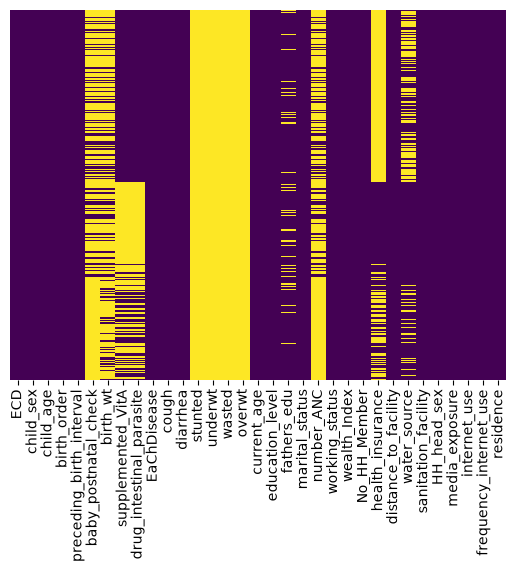

In [14]:
#Visualise missing values if there is/ We are using a cleaned data, so no missing data for now
sns.heatmap(data.isnull(),yticklabels=False,cbar=False,cmap='viridis')

In [15]:
#dropping a variable with missing >=40%#
data= data.drop('birth_wt', axis=1)
data= data.drop('baby_postnatal_check', axis=1)
data= data.drop('stunted', axis=1)
data= data.drop('wasted', axis=1)
data= data.drop('underwt', axis=1)
data= data.drop('overwt', axis=1)
data= data.drop('number_ANC', axis=1)
data= data.drop('fathers_edu', axis=1)
data= data.drop('health_insurance', axis=1)
data= data.drop('frequency_internet_use', axis=1)
#Extra variables with missing values
data= data.drop('water_source', axis=1)
data= data.drop('drug_intestinal_parasite', axis=1)
data= data.drop('supplemented_VitA', axis=1)

Text(0, 0.5, 'Frequency')

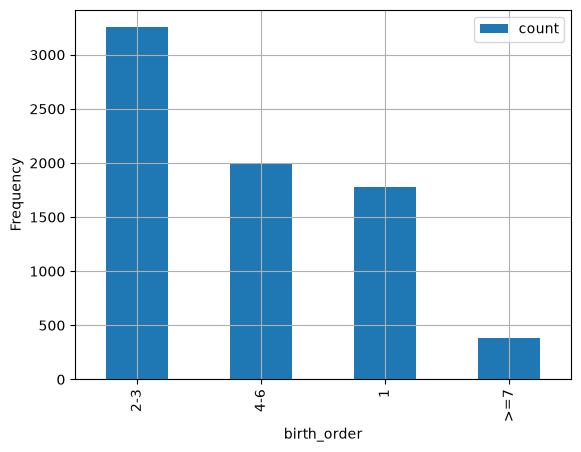

In [16]:
#We can do a specific and detailed assesment of each variable.
#For example, let's see the distribution of number of birth_order, Age and blood pressure
data.birth_order.value_counts().plot(kind = "bar")
plt.legend()
plt.grid(True)
plt.xlabel('birth_order')
plt.ylabel('Frequency')

In [17]:
from sklearn.preprocessing import LabelEncoder 

In [18]:
# Convert categorical data to numerical data using LabelEncoder 
le = LabelEncoder()
data['child_sex'] = le.fit_transform(data['child_sex'])
data['child_age'] = le.fit_transform(data['child_age'])
data['residence'] = le.fit_transform(data['residence'])
# data['supplemented_VitA'] = le.fit_transform(data['supplemented_VitA'])
# data['drug_intestinal_parasite'] = le.fit_transform(data['drug_intestinal_parasite'])
data['HH_head_sex'] = le.fit_transform(data['HH_head_sex'])
data['birth_order'] = le.fit_transform(data['birth_order'])
data['preceding_birth_interval'] = le.fit_transform(data['preceding_birth_interval'])
data['EaChDisease'] = le.fit_transform(data['EaChDisease'])
data['current_age'] = le.fit_transform(data['current_age'])
data['education_level'] = le.fit_transform(data['education_level'])
data['marital_status'] = le.fit_transform(data['marital_status'])
data['working_status'] = le.fit_transform(data['working_status'])
data['wealth_Index'] = le.fit_transform(data['wealth_Index'])
data['distance_to_facility'] = le.fit_transform(data['distance_to_facility'])
data['media_exposure'] = le.fit_transform(data['media_exposure'])
data['No_HH_Member'] = le.fit_transform(data['No_HH_Member'])
data['diarrhea'] = le.fit_transform(data['diarrhea'])
data['cough'] = le.fit_transform(data['cough'])
data['internet_use'] = le.fit_transform(data['internet_use'])
data['sanitation_facility'] = le.fit_transform(data['sanitation_facility'])

In [19]:
# View the converted DataFrame
print(data)

      ECD  child_sex  child_age  birth_order  preceding_birth_interval  \
0     1.0          0          2            1                         2   
1     1.0          0          1            1                         2   
2     1.0          1          0            0                         1   
3     1.0          0          0            1                         2   
4     1.0          0          1            2                         2   
...   ...        ...        ...          ...                       ...   
7406  1.0          1          1            1                         2   
7407  1.0          1          2            1                         0   
7408  1.0          0          0            0                         1   
7409  1.0          1          0            1                         2   
7410  0.0          1          2            2                         2   

      EaChDisease  cough  diarrhea  current_age  education_level  \
0               0      0         0         

In [20]:
#see the value counts of variables
print (data["child_sex"].value_counts())
print (data["child_age"].value_counts())
print (data["education_level"].value_counts())
print (data["media_exposure"].value_counts())
# print (data["drug_intestinal_parasite"].value_counts())
print (data["current_age"].value_counts())
print (data["wealth_Index"].value_counts())
print (data["EaChDisease"].value_counts())

child_sex
1    3845
0    3566
Name: count, dtype: int64
child_age
1    2642
0    2388
2    2381
Name: count, dtype: int64
education_level
2    6275
1     990
0     146
Name: count, dtype: int64
media_exposure
0    6357
1    1054
Name: count, dtype: int64
current_age
0    5103
1    2237
2      71
Name: count, dtype: int64
wealth_Index
1    4358
2    1793
0    1260
Name: count, dtype: int64
EaChDisease
0    5758
1    1653
Name: count, dtype: int64


In [21]:
# Now lets see the correlation with in the variables in the dataset
data.corr() #This function is the default pearson correlation function.

,ECD,child_sex,child_age,birth_order,preceding_birth_interval,EaChDisease,cough,diarrhea,current_age,education_level,marital_status,working_status,wealth_Index,No_HH_Member,distance_to_facility,sanitation_facility,HH_head_sex,media_exposure,internet_use,residence
ECD,1.000000,-0.064008,-0.083956,-0.046445,0.008847,0.049417,0.039792,0.029765,-0.007687,0.133750,0.013053,0.056300,0.022366,-0.004044,0.078208,-0.078123,0.017656,-0.089995,0.132479,0.028100
child_sex,-0.064008,1.000000,0.013679,-0.004197,-0.013249,0.004142,0.001873,-0.000065,-0.006256,-0.010665,0.012625,0.013892,0.000198,0.001442,-0.000898,0.005740,-0.009608,0.010175,-0.007474,0.004655
child_age,-0.083956,0.013679,1.000000,0.026321,-0.011220,-0.040988,-0.021861,-0.058837,0.045682,-0.021741,-0.019810,0.058327,0.009363,-0.020317,-0.007415,-0.002582,-0.008102,0.003851,-0.011795,-0.017965
birth_order,-0.046445,-0.004197,0.026321,1.000000,0.257790,-0.002423,0.002914,-0.006063,0.390927,-0.216306,-0.241880,-0.019995,-0.063893,0.399771,-0.100408,-0.010567,0.103173,0.045800,-0.218058,0.008114
preceding_birth_interval,0.008847,-0.013249,-0.011220,0.257790,1.000000,-0.005202,-0.005986,-0.015589,0.178247,-0.004964,-0.035733,0.078840,0.010675,0.053603,0.003592,-0.021061,0.012680,0.013789,-0.053863,-0.063669
EaChDisease,0.049417,0.004142,-0.040988,-0.002423,-0.005202,1.000000,0.796587,0.462062,-0.007740,0.025000,0.039487,0.035992,-0.014679,-0.001161,-0.025314,-0.033473,-0.001223,-0.042774,0.043417,-0.019881
cough,0.039792,0.001873,-0.021861,0.002914,-0.005986,0.796587,1.000000,0.144269,-0.020410,0.018855,0.031734,0.020988,-0.008282,0.010719,-0.020421,-0.023415,-0.002882,-0.035757,0.051084,-0.002601
diarrhea,0.029765,-0.000065,-0.058837,-0.006063,-0.015589,0.462062,0.144269,1.000000,-0.000466,0.016301,0.000700,-0.006538,-0.008871,-0.018278,0.005724,-0.036884,0.019343,-0.008066,0.027889,0.016360
current_age,-0.007687,-0.006256,0.045682,0.390927,0.178247,-0.007740,-0.020410,-0.000466,1.000000,-0.084634,-0.089674,0.100248,0.061652,0.171170,-0.023112,-0.033237,-0.001946,0.001314,-0.127060,-0.023719
education_level,0.133750,-0.010665,-0.021741,-0.216306,-0.004964,0.025000,0.018855,0.016301,-0.084634,1.000000,0.021309,0.059882,0.055076,-0.100144,0.152347,-0.164757,-0.043918,-0.177873,0.316892,0.073989


<Axes: >

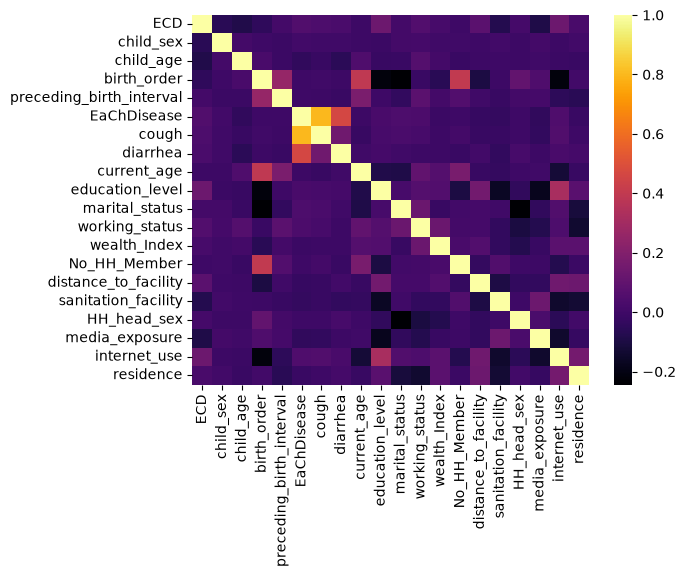

In [22]:
#see the correlation heatmap
sns.heatmap(data.corr(), cmap='inferno') #Very good correlation 

In [23]:
data["child_sex"].value_counts()

child_sex
1    3845
0    3566
Name: count, dtype: int64

In [24]:
data['ECD'].corr(data['child_sex'])

np.float64(-0.06400757725003889)

In [25]:
corr= data.corr()

In [26]:
# Getting the Upper Triangle of the co-relation matrix
matrix = np.triu(np.ones_like(corr))

<Axes: >

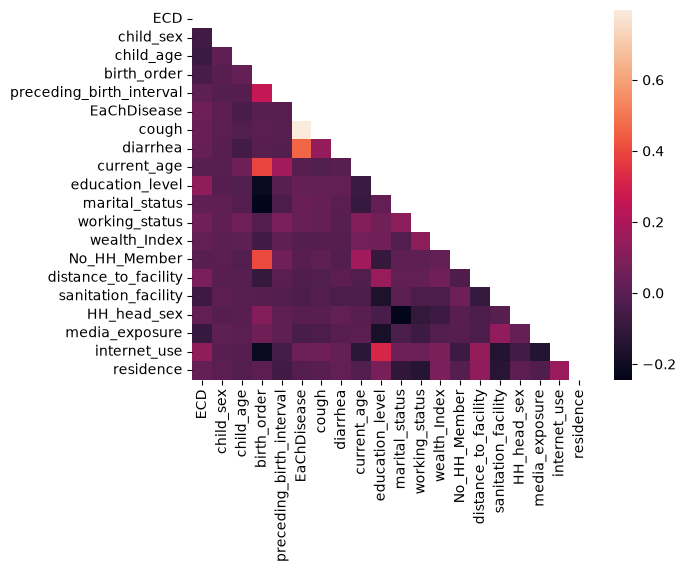

In [27]:
# using the upper triangle matrix as mask 
sns.heatmap(data.corr(), mask=matrix)

In [28]:
#Defining the outcome variable and the independent variables/ECD in our case
X= data.drop(["ECD"], axis = 1)
Y= data["ECD"]

In [29]:
Y

0       1.0
1       1.0
2       1.0
3       1.0
4       1.0
       ... 
7406    1.0
7407    1.0
7408    1.0
7409    1.0
7410    0.0
Name: ECD, Length: 7411, dtype: float64

<Axes: xlabel='ECD', ylabel='count'>

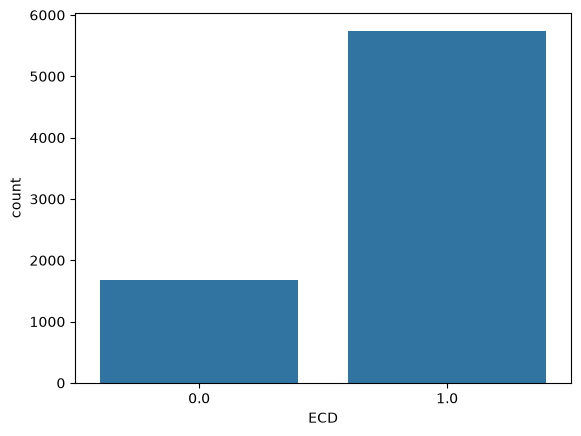

In [30]:
#See if the outcome variable is balanced
sns.countplot(x='ECD', data=data)

In [31]:
# Train/Test split
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size = 0.2, random_state = 42)

In [32]:
#From the resampling comparision file, we can see that the baseline model performed relatively better and we proceed using it to develope the model used in this study

In [33]:
# see the shape of the resampled dataset
print("x_train : ",x_train.shape)

x_train :  (5928, 19)


In [34]:
print("x_test : ",x_test.shape)

x_test :  (1483, 19)


In [35]:
print("y_train : ",y_train.shape)

y_train :  (5928,)


In [36]:
print("y_test : ",y_test.shape)

y_test :  (1483,)


In [37]:
# Convert the arrays or DataFrames to DataFrames if needed
x_train_df = pd.DataFrame(x_train)
x_test_df = pd.DataFrame(x_test)
y_train_df = pd.DataFrame(y_train)
y_test_df = pd.DataFrame(y_test)

In [38]:
#From the model comparision module, we identified that three models perform better (RF and XGB)
#Training the first model, rf
#rf gride search (done) and model training
# from sklearn.ensemble import RandomForestClassifier
# rfc_tuned = RandomForestClassifier(criterion = 'gini', max_depth = 4, max_features= 'sqrt', min_samples_leaf= 1, min_samples_split= 10, n_estimators = 50, random_state = 42)
# rfc_tuned.fit(x_train, y_train)

#NB grid search (done) and model training
from sklearn.naive_bayes import GaussianNB
nb_tuned = GaussianNB(var_smoothing= 0.008111308307896872)
nb_tuned.fit(x_train, y_train)

,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",0.008111308307896872
,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[1335.,4593.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.23,0.77]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[float64](2,)","[0.,1.]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.006039
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](19,)","['child_sex','child_age','birth_order',...,'media_exposure','internet_use', 'residence']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,19
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 19)","[[0.58,1.14,1.21,...,0.2 ,1.29,0.52], [0.51,0.97,1.11,...,0.13,1.56,0.55]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 19)","[[0.25,0.66,0.74,...,0.17,0.91,0.26], [0.26,0.64,0.69,...,0.12,0.69,0.25]]"


In [39]:
# Make predictions on the test set
# rfc_pred= rfc_tuned.predict(x_test)

Nbpred = nb_tuned.predict(x_test)

In [40]:
# %pip install xgboost

In [41]:
#Training the second model, XGB
#XGB grid search(done) and model training
# from xgboost import XGBClassifier
# xgb_tuned=XGBClassifier(learning_rate= 0.01, max_depth= 3, n_estimators= 200)
# xgb_tuned.fit(x_train, y_train)

#GB grid search (done) and model training
from sklearn.ensemble import GradientBoostingClassifier
gb_tuned = GradientBoostingClassifier(learning_rate=0.1, n_estimators=200, max_depth=5)
gb_tuned.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",5
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"init init: estimator or 'zero', default=NoneAn estimator object that is used to co

In [42]:
# Make predictions on the test set
# XGBpred= xgb_tuned.predict(x_test)

GBpred = gb_tuned.predict(x_test)

In [43]:
# Ensemling the models
# Import required libraries
from sklearn.ensemble import VotingClassifier

In [44]:
# Create an ensemble model using VotingClassifier based on the best model from the model comparison file
# ensemble_model = VotingClassifier(estimators=[('rf',rfc_tuned), ('xgb', xgb_tuned)], voting='soft')
ensemble_model = VotingClassifier(estimators=[('nb',nb_tuned), ('gb', gb_tuned)], voting='soft')

In [45]:
# Fit the ensemble model to the data
ensemble_model.fit(x_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('nb', ...), ('gb', ...)]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[float64](2,)","[0.,1.]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[GaussianNB(va...1308307896872), GradientBoost...stimators=200)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['child_sex','child_age','birth_order',...,'media_exposure','internet_use', 'residence']"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()


In [46]:
# Predict the target variable
y_pred_ensemble = ensemble_model.predict(x_train)

In [47]:
from sklearn.metrics import classification_report
print(classification_report(y_train, y_pred_ensemble))

              precision    recall  f1-score   support

         0.0       0.54      0.28      0.37      1335
         1.0       0.82      0.93      0.87      4593

    accuracy                           0.78      5928
   macro avg       0.68      0.61      0.62      5928
weighted avg       0.75      0.78      0.76      5928



In [48]:
# Ensure the predictions have the same number of samples
# min_samples = min(len(rfc_pred), len(XGBpred))
# rf_predictions = rfc_pred[:min_samples]
# xgb_predictions = XGBpred[:min_samples]
# y_test = y_test[:min_samples]


min_samples = min(len(Nbpred), len(GBpred))
nb_predictions = Nbpred[:min_samples]
gb_predictions = GBpred[:min_samples]
y_test = y_test[:min_samples]

In [49]:
# ensemble_predictions = []
# for i in range(len(y_test)):
#     # Majority voting
#     votes = rfc_pred[i] + XGBpred[i]
#     ensemble_predictions.append(1 if votes >= 2 else 0)

ensemble_predictions = []
for i in range(len(y_test)):
    # Majority voting
    votes = Nbpred[i] + GBpred[i]
    ensemble_predictions.append(1 if votes >= 2 else 0)

In [50]:
# calculating the metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import recall_score
cm = confusion_matrix(y_test, ensemble_predictions)

In [51]:
# calculate sensitivity/recall
sensitivity = recall_score(y_test, ensemble_predictions)
# calculate specificity
specificity = cm[0,0] / (cm[0,0] + cm[0,1])
# print the results
print("Sensitivity:", sensitivity)
print("Specificity:", specificity)

Sensitivity: 0.8526591107236269
Specificity: 0.33630952380952384


In [52]:
# Use learning_curve to generate the training and test accuracy scores
from sklearn.model_selection import learning_curve, train_test_split
train_sizes, train_scores, test_scores = learning_curve(ensemble_model, x_train, y_train, cv=10)

In [53]:
# Calculate the mean and standard deviation of the training and test accuracy scores
train_scores_mean = np.mean(train_scores, axis=1)
train_scores_std = np.std(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)
test_scores_std = np.std(test_scores, axis=1)

In [54]:
#results#
print (train_scores_mean)
print (train_scores_std)
print (test_scores_mean)
print (test_scores_std)

[0.94746717 0.84050779 0.80654397 0.79712143 0.78903468]
[0.00562852 0.00373248 0.00273601 0.00212828 0.00177872]
[0.72081577 0.74915882 0.75658129 0.75084716 0.75455882]
[0.01798851 0.01448818 0.0117337  0.00944663 0.01357081]


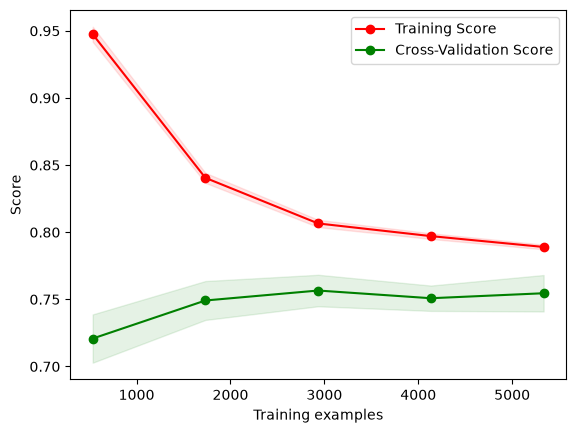

In [55]:
# Plot the learning curve
plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Training Score")
plt.plot(train_sizes, test_scores_mean, 'o-', color="g", label="Cross-Validation Score")
plt.fill_between(train_sizes, train_scores_mean - train_scores_std, train_scores_mean + train_scores_std, alpha=0.1, color="r")
plt.fill_between(train_sizes, test_scores_mean - test_scores_std, test_scores_mean + test_scores_std, alpha=0.1, color="g")
plt.xlabel("Training examples")
plt.ylabel("Score")
plt.legend(loc="best")
plt.show()

In [56]:
# Extract feature importances from the base classifiers
# rf_feature_importances = rfc_tuned.feature_importances_
# xgb_feature_importances = xgb_tuned.feature_importances_

from sklearn.inspection import permutation_importance

nb_result = permutation_importance(
    nb_tuned,
    x_test,
    y_test,
    scoring="balanced_accuracy",
    n_repeats=10,
    random_state=42
)

nb_feature_importances = nb_result.importances_mean
gb_feature_importances = gb_tuned.feature_importances_

In [57]:
# Calculate average feature importance across the Gradient Boosting and XGBoost classifiers
ensemble_feature_importances = (nb_feature_importances + gb_feature_importances ) / 2

In [58]:
# Sort feature importances in descending order
sorted_indices = np.argsort(ensemble_feature_importances)[::-1]
sorted_importances = ensemble_feature_importances[sorted_indices]
sorted_features = np.arange(X.shape[1])[sorted_indices]

In [59]:
sorted_features

array([ 8, 17,  1, 12,  2, 11, 18,  3, 13, 14, 16, 10, 15,  7,  0,  9,  5,
        4,  6])

In [60]:
ensemble_feature_importances

array([0.02255023, 0.04333289, 0.03854385, 0.03034383, 0.01258618,
       0.0177592 , 0.01056432, 0.02370419, 0.04902243, 0.01974992,
       0.0238578 , 0.03507357, 0.04040021, 0.02742557, 0.02512088,
       0.02373506, 0.02491209, 0.04893272, 0.03116221])

In [61]:
# Create a list of feature names
feature_names = X.columns
feature_names

Index(['child_sex', 'child_age', 'birth_order', 'preceding_birth_interval',
       'EaChDisease', 'cough', 'diarrhea', 'current_age', 'education_level',
       'marital_status', 'working_status', 'wealth_Index', 'No_HH_Member',
       'distance_to_facility', 'sanitation_facility', 'HH_head_sex',
       'media_exposure', 'internet_use', 'residence'],
      dtype='str')

In [62]:
feature_importances = pd.DataFrame(ensemble_feature_importances, index= feature_names)
feature_importances.head()

,0
child_sex,0.022550
child_age,0.043333
birth_order,0.038544
preceding_birth_interval,0.030344
EaChDisease,0.012586


In [63]:
features = list(feature_importances [feature_importances[0]>0].index)
features

['child_sex',
 'child_age',
 'birth_order',
 'preceding_birth_interval',
 'EaChDisease',
 'cough',
 'diarrhea',
 'current_age',
 'education_level',
 'marital_status',
 'working_status',
 'wealth_Index',
 'No_HH_Member',
 'distance_to_facility',
 'sanitation_facility',
 'HH_head_sex',
 'media_exposure',
 'internet_use',
 'residence']

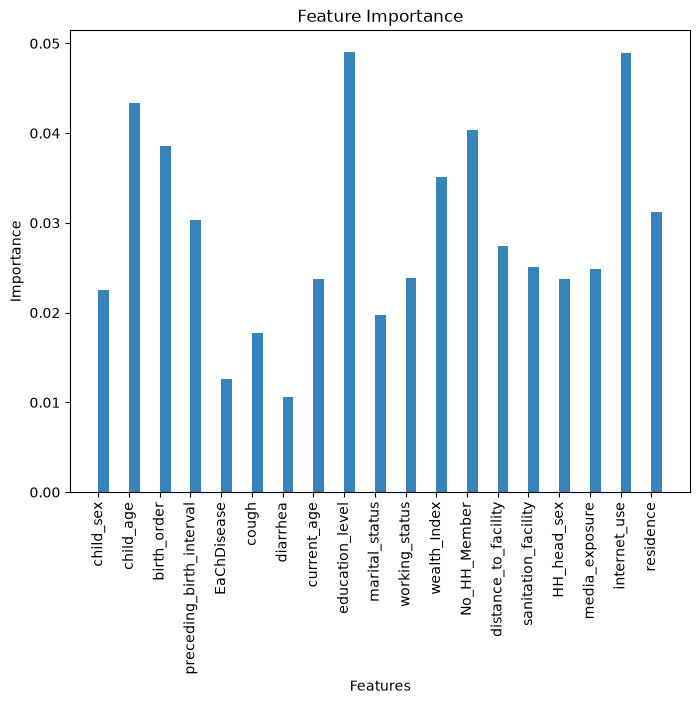

In [64]:
# Plot the feature importances
plt.figure( figsize=(8, 6))
plt.bar(np.arange(len(feature_names)), feature_importances[0], alpha=0.9, width=0.35, align='edge', label='Ensemble model')
plt.xticks(np.arange(len(feature_names)), feature_names, rotation=90)
plt.xlabel('Features')
plt.ylabel('Importance')
plt.title('Feature Importance')
plt.savefig('newa.tiff', bbox_inches="tight",dpi = 700)

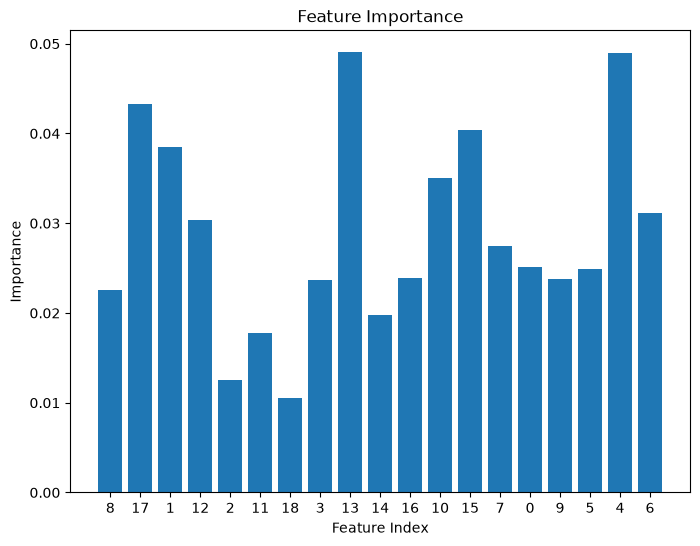

In [65]:
# Plot the feature importances
plt.figure(figsize=(8, 6))
plt.bar(range(X.shape[1]), ensemble_feature_importances, align='center')
plt.xticks(range(X.shape[1]), sorted_features)
plt.xlabel('Feature Index')
plt.ylabel('Importance')
plt.title('Feature Importance')
plt.show()

In [66]:
# Plot the SHAP values
def model_predict(x_test):
    return ensemble_model.predict(x_test)

In [67]:
%pip install shap


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [68]:
import shap
explainer = shap.Explainer(model_predict, x_test)
shap_values = explainer(x_test)

Background dataset has 1483 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1483 when initializing the masker.
PermutationExplainer explainer: 1484it [03:31,  6.71it/s]                          


/tmp/ipykernel_170946/718511808.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, x_test)


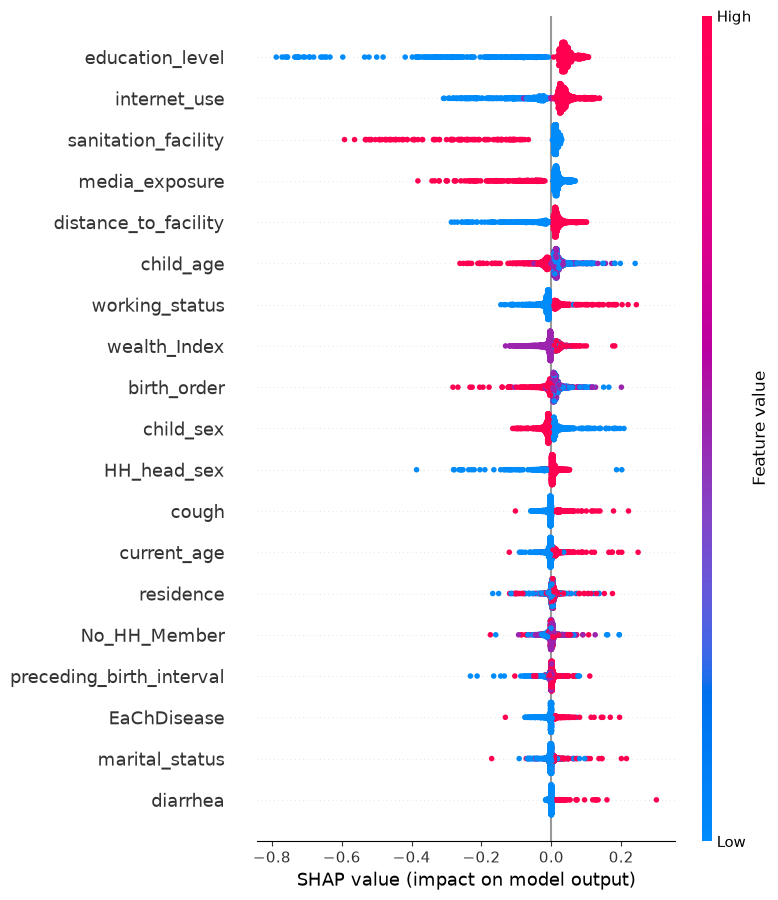

In [69]:
shap.summary_plot(shap_values, x_test)

In [70]:
#compute shap values
explainer = shap.Explainer(model_predict, x_test)
shap_values = explainer(x_test)

Background dataset has 1483 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1483 when initializing the masker.
PermutationExplainer explainer: 1484it [03:29,  6.73it/s]                          


In [71]:
# Check if shap_values is a vector, and if so, convert it to a matrix
if len(shap_values.shape) == 1:
    shap_values = shap_values.reshape((-1, x_test.shape[1]))

/tmp/ipykernel_170946/2960424795.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values.data, x_test.values, feature_names = x_test.columns)


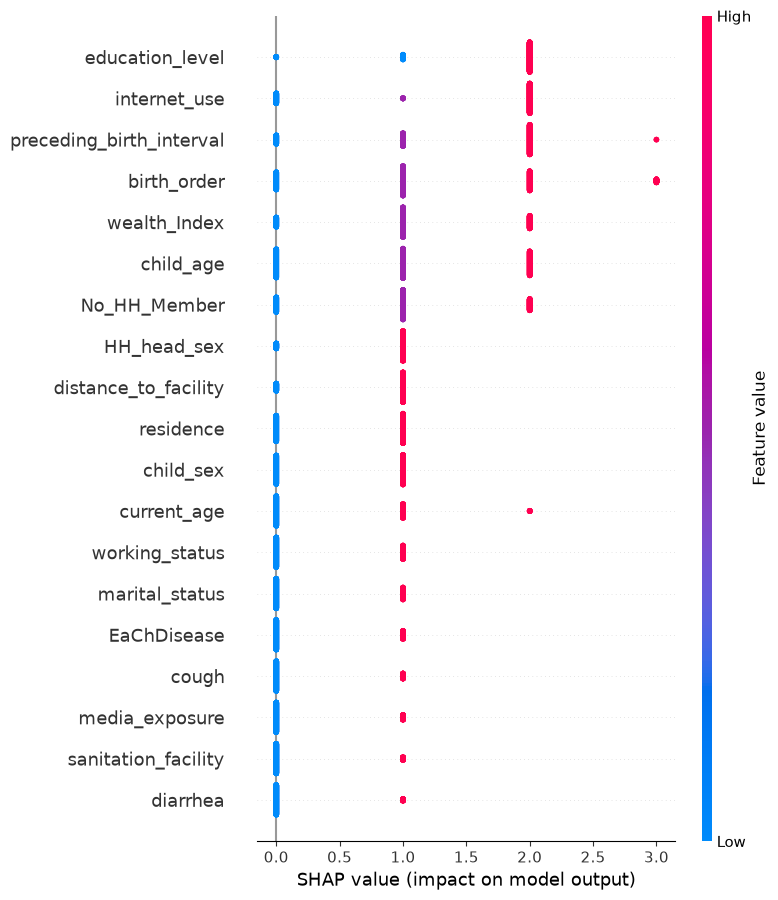

(1483, 19)

In [72]:
shap.summary_plot(shap_values.data, x_test.values, feature_names = x_test.columns)
x_test.shape

In [73]:
#compute shap values
explainer = shap.Explainer(model_predict, x_test)
shap_values = explainer(x_test)

Background dataset has 1483 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1483 when initializing the masker.
PermutationExplainer explainer: 1484it [03:27,  6.80it/s]                          


In [74]:
# Check if shap_values is a vector, and if so, convert it to a matrix
if len(shap_values.shape) == 1:
    shap_values = shap_values.reshape((-1, x_test.shape[1]))

/tmp/ipykernel_170946/2146724385.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values.data, x_test.values, feature_names = x_test.columns, plot_type = "violin")


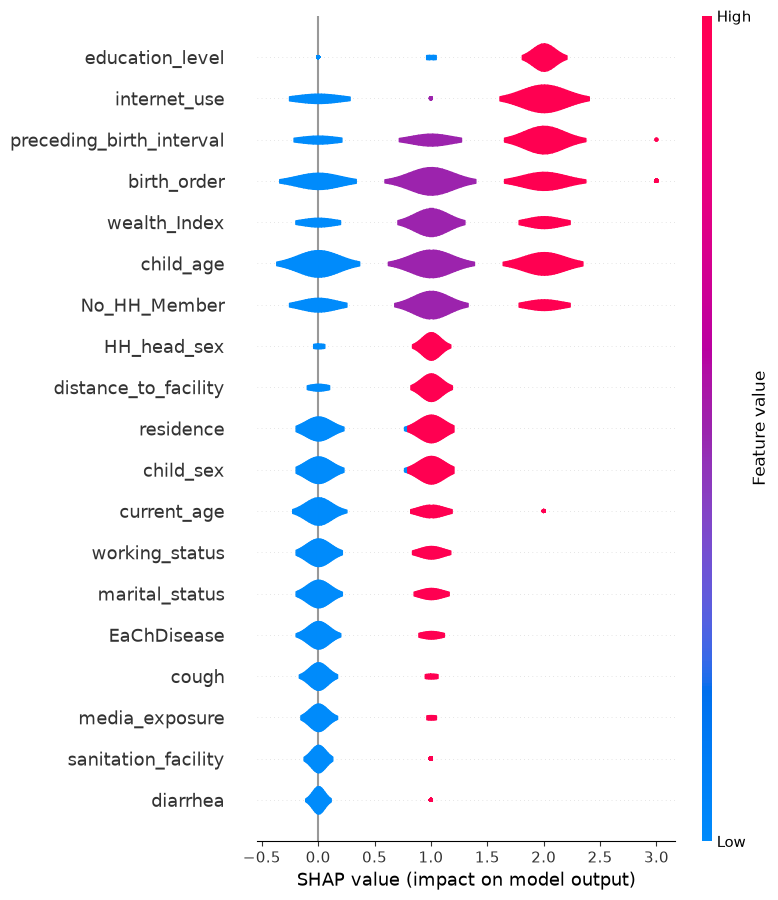

In [75]:
shap.summary_plot(shap_values.data, x_test.values, feature_names = x_test.columns, plot_type = "violin")

In [76]:
#compute shap values
explainer = shap.Explainer(model_predict, x_test)
shap_values = explainer(x_test)

Background dataset has 1483 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1483 when initializing the masker.
PermutationExplainer explainer: 1484it [03:23,  6.95it/s]                          


In [77]:
# Check if shap_values is a vector, and if so, convert it to a matrix
if len(shap_values.shape) == 1:
    shap_values = shap_values.reshape((-1, x_test.shape[1]))

/tmp/ipykernel_170946/718511808.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, x_test)


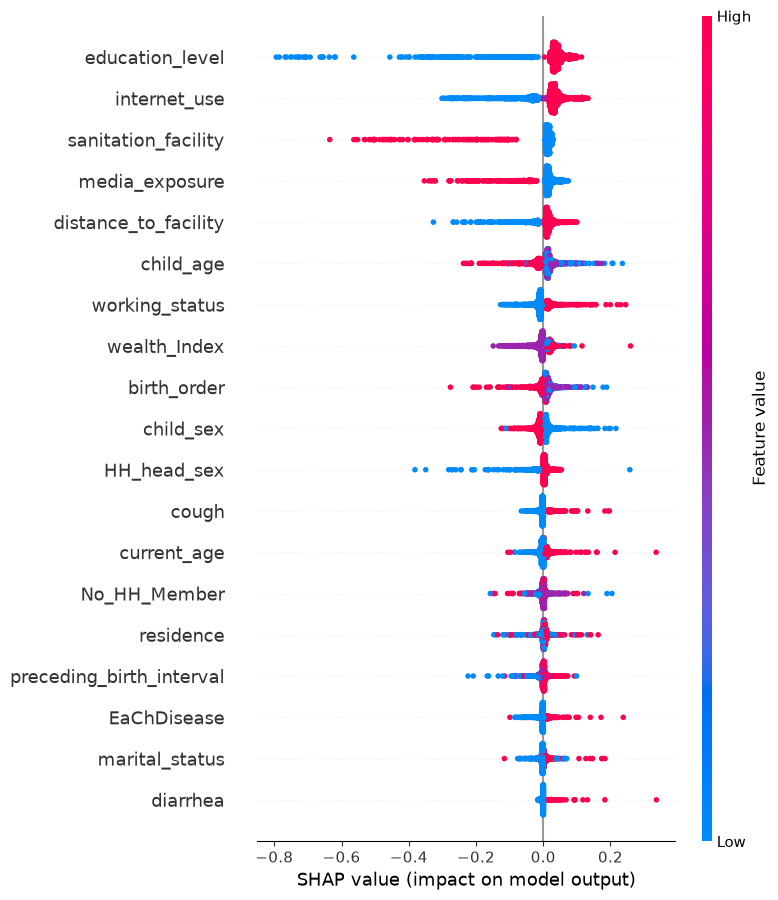

In [78]:
shap.summary_plot(shap_values, x_test)

In [79]:
#compute shap values
explainer = shap.Explainer(model_predict, x_test)
shap_values = explainer(x_test)

Background dataset has 1483 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1483 when initializing the masker.


PermutationExplainer explainer: 1484it [03:28,  6.79it/s]                          


In [80]:
# Check if shap_values is a vector, and if so, convert it to a matrix
if len(shap_values.shape) == 1:
    shap_values = shap_values.reshape((-1, x_test.shape[1]))

In [81]:
import matplotlib.pyplot as pl

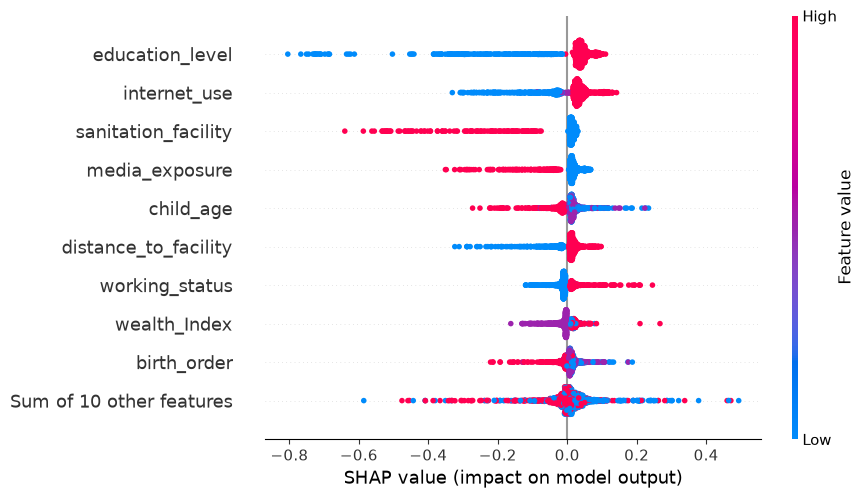

In [82]:
shap.plots.beeswarm(shap_values, show=False)
pl.savefig("shap.tiff",bbox_inches="tight", dpi=700)

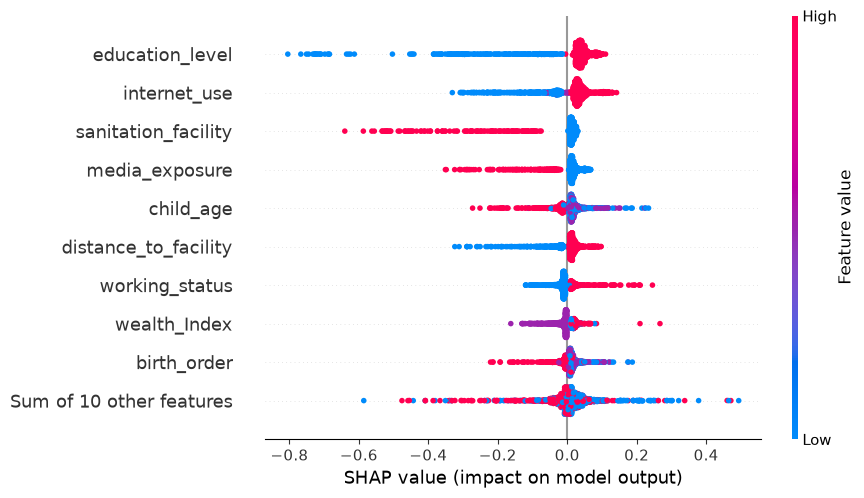

In [83]:
shap.plots.beeswarm(shap_values) #shap.plots.beeswarm(shap_values, plot_type= "violin")# ... this was the original code

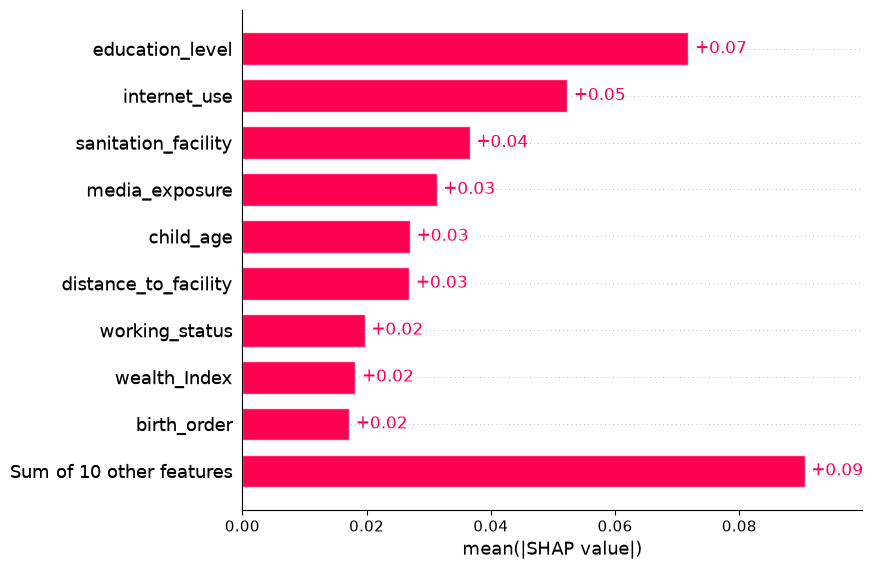

In [84]:
shap.plots.bar(shap_values, show=False)
pl.savefig("shap_values.tiff",bbox_inches="tight", dpi=700)

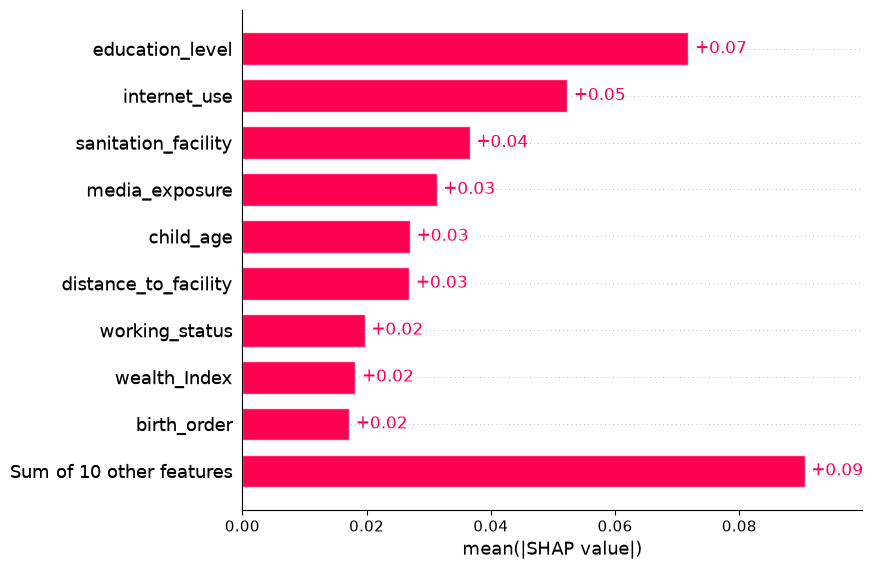

In [85]:
shap.plots.bar(shap_values)

In [86]:
shap_values.values.max(axis=0)

array([0.19125   , 0.23416667, 0.1875    , 0.10166667, 0.2125    ,
       0.21875   , 0.35583333, 0.28416667, 0.11041667, 0.21916667,
       0.24541667, 0.26708333, 0.22      , 0.0975    , 0.03041667,
       0.12583333, 0.0675    , 0.14208333, 0.17916667])

In [87]:
shap_values.values.min(axis=0)

array([-0.12166667, -0.2725    , -0.22083333, -0.22083333, -0.12416667,
       -0.06208333, -0.01541667, -0.13375   , -0.80458333, -0.09958333,
       -0.12      , -0.1625    , -0.17375   , -0.32375   , -0.64041667,
       -0.35541667, -0.35083333, -0.33083333, -0.16708333])

In [88]:
min_shap = shap_values.values.min(axis=0)
max_shap = shap_values.values.max(axis=0)

shap_summary = pd.DataFrame({
    'Feature': feature_names,
    'Min_SHAP': min_shap,
    'Max_SHAP': max_shap
})

In [89]:
print("\n=== Min and Max SHAP Values Table (Class 1 Prediction) ===")
print(shap_summary)


=== Min and Max SHAP Values Table (Class 1 Prediction) ===
                     Feature  Min_SHAP  Max_SHAP
0                  child_sex -0.121667  0.191250
1                  child_age -0.272500  0.234167
2                birth_order -0.220833  0.187500
3   preceding_birth_interval -0.220833  0.101667
4                EaChDisease -0.124167  0.212500
5                      cough -0.062083  0.218750
6                   diarrhea -0.015417  0.355833
7                current_age -0.133750  0.284167
8            education_level -0.804583  0.110417
9             marital_status -0.099583  0.219167
10            working_status -0.120000  0.245417
11              wealth_Index -0.162500  0.267083
12              No_HH_Member -0.173750  0.220000
13      distance_to_facility -0.323750  0.097500
14       sanitation_facility -0.640417  0.030417
15               HH_head_sex -0.355417  0.125833
16            media_exposure -0.350833  0.067500
17              internet_use -0.330833  0.142083
18       

In [90]:
shap_summary

,Feature,Min_SHAP,Max_SHAP
0,child_sex,-0.121667,0.191250
1,child_age,-0.272500,0.234167
2,birth_order,-0.220833,0.187500
3,preceding_birth_interval,-0.220833,0.101667
4,EaChDisease,-0.124167,0.212500
5,cough,-0.062083,0.218750
6,diarrhea,-0.015417,0.355833
7,current_age,-0.133750,0.284167
8,education_level,-0.804583,0.110417
9,marital_status,-0.099583,0.219167


In [91]:
#visualize the first prediction's explanation with default colors
shap.initjs()
shap.plots.force(shap_values[0,:])

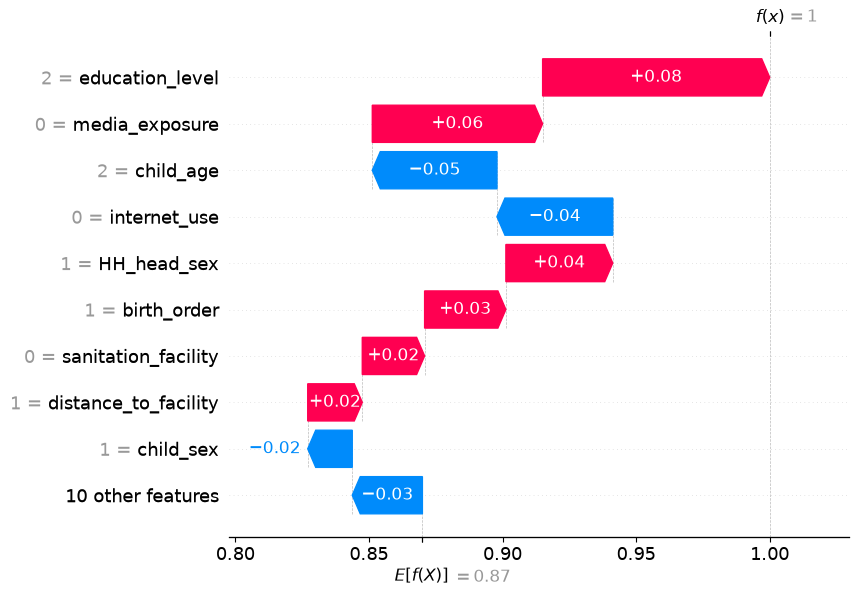

In [92]:
shap.plots.waterfall(shap_values[2])

In [93]:
#compute shap values
explainer = shap.Explainer(model_predict, x_test)
shap_values = explainer(x_test)

Background dataset has 1483 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1483 when initializing the masker.
PermutationExplainer explainer: 1484it [03:28,  6.79it/s]                          


In [94]:
# Check if shap_values is a vector, and if so, convert it to a matrix
if len(shap_values.shape) == 1:
    shap_values = shap_values.reshape((-1, x_test.shape[1]))

/tmp/ipykernel_170946/7583183.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, plot_type = "violin")


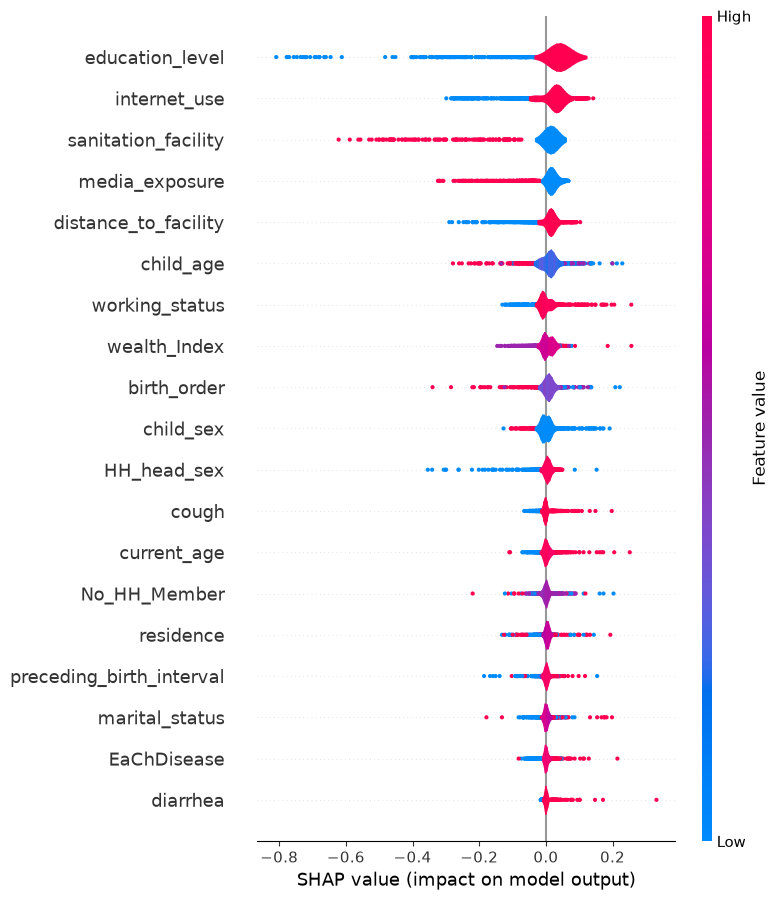

In [95]:
shap.summary_plot(shap_values, plot_type = "violin")

In [96]:
#compute shap values
explainer = shap.Explainer(model_predict, x_test)
shap_values = explainer(x_test)

Background dataset has 1483 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1483 when initializing the masker.
PermutationExplainer explainer: 1484it [03:25,  6.86it/s]                          


In [97]:
# Check if shap_values is a vector, and if so, convert it to a matrix
if len(shap_values.shape) == 1:
    shap_values = shap_values.reshape((-1, x_test.shape[1]))

/tmp/ipykernel_170946/2146724385.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values.data, x_test.values, feature_names = x_test.columns, plot_type = "violin")


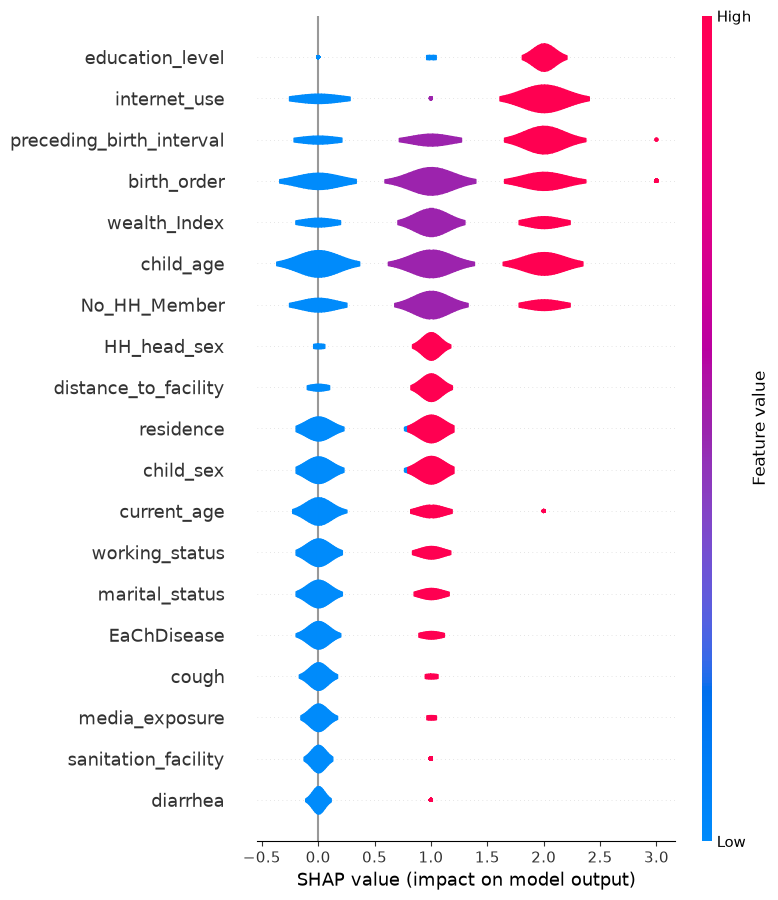

In [98]:
shap.summary_plot(shap_values.data, x_test.values, feature_names = x_test.columns, plot_type = "violin")